In [1]:
using CairoMakie
using TOML
using Statistics

In [ ]:
n = [1, 2, 4]

user = ENV["USER"]

ds4 = [TOML.parsefile("/nfs/hpc/share/"*user*"/ngpu-scaling/weak/4-gpu_stats"*string(i)*".toml") for i = 0:3]
ds2 = [TOML.parsefile("/nfs/hpc/share/"*user*"/ngpu-scaling/weak/2-gpu_stats"*string(i)*".toml") for i = 0:1]
ds1 = [TOML.parsefile("/nfs/hpc/share/"*user*"/ngpu-scaling/weak/1-gpu_stats"*string(i)*".toml") for i = 0:0]

mem_tot = [sum([i["used_mem"] for i in ds1]), sum([i["used_mem"] for i in ds2]), sum([i["used_mem"] for i in ds4])] ./ 1024
mem_per = mem_tot ./ n

times = [mean([i["runtime"] for i in ds1]), mean([i["runtime"] for i in ds2]), mean([i["runtime"] for i in ds4])] ./ 60



3-element Vector{Float64}:
 46.416666666666664
 45.75
 54.1625

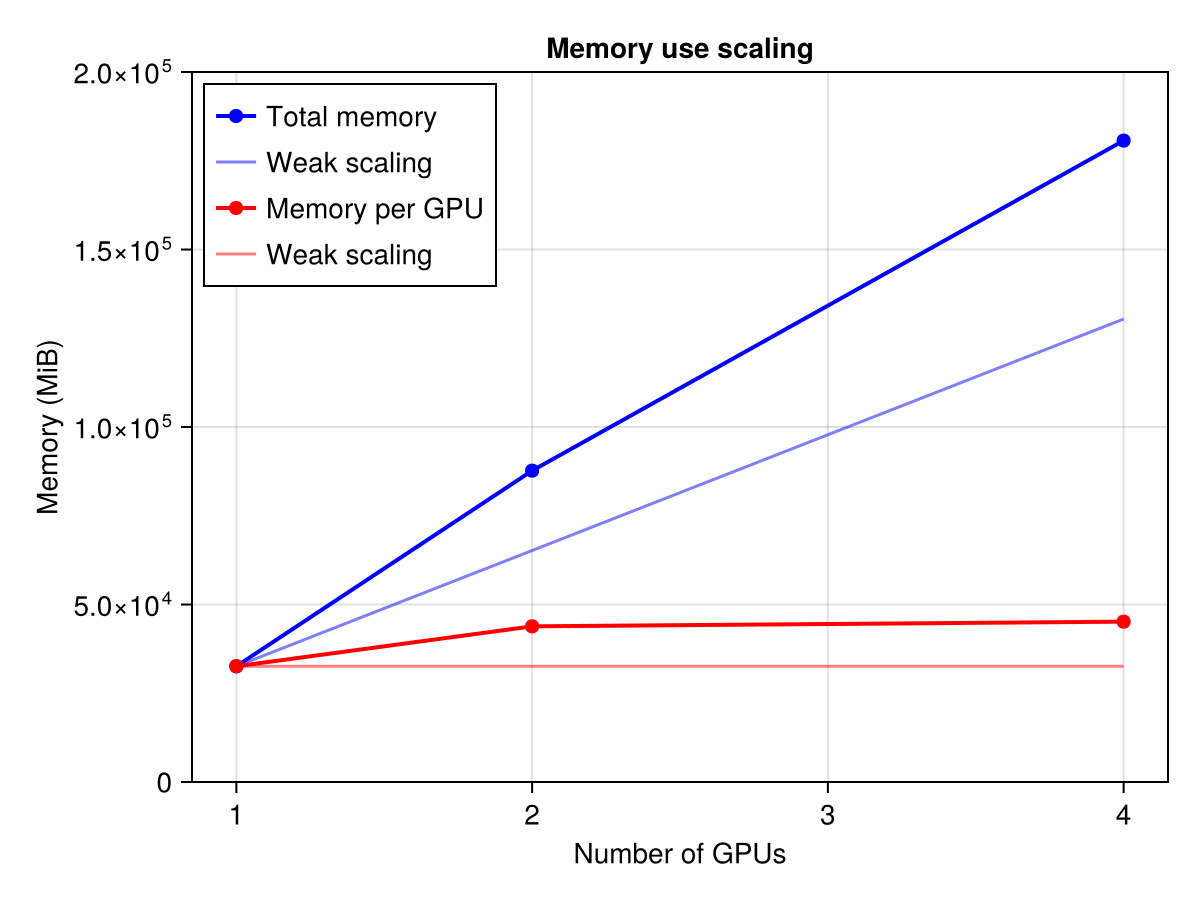

In [7]:
f = Figure()
ax = Axis(f[1, 1], xlabel = "Number of GPUs", ylabel = "Memory (MiB)", title = "Memory use scaling")
scatterlines!(ax, n, mem_tot, linewidth = 2, label = "Total memory", marker = :circle, markersize = 10, color = :blue)
lines!(ax, range(1, 4, 100), range(mem_tot[1], mem_tot[1]*4, 100), color = :blue, label = "Weak scaling", alpha = 0.5)
scatterlines!(ax,
    n,
    mem_per,
    linewidth = 2,
    label = "Memory per GPU",
    marker = :circle,
    markersize = 10,
    color = :red,
)
lines!(ax, range(1, 4, 100), range(mem_tot[1], mem_tot[1], 100), color = :red, label = "Weak scaling", alpha = 0.5)
ylims!(ax, 0, 2*10^5)
axislegend(ax, position = :lt)
save("mem_weak.svg", f)
f

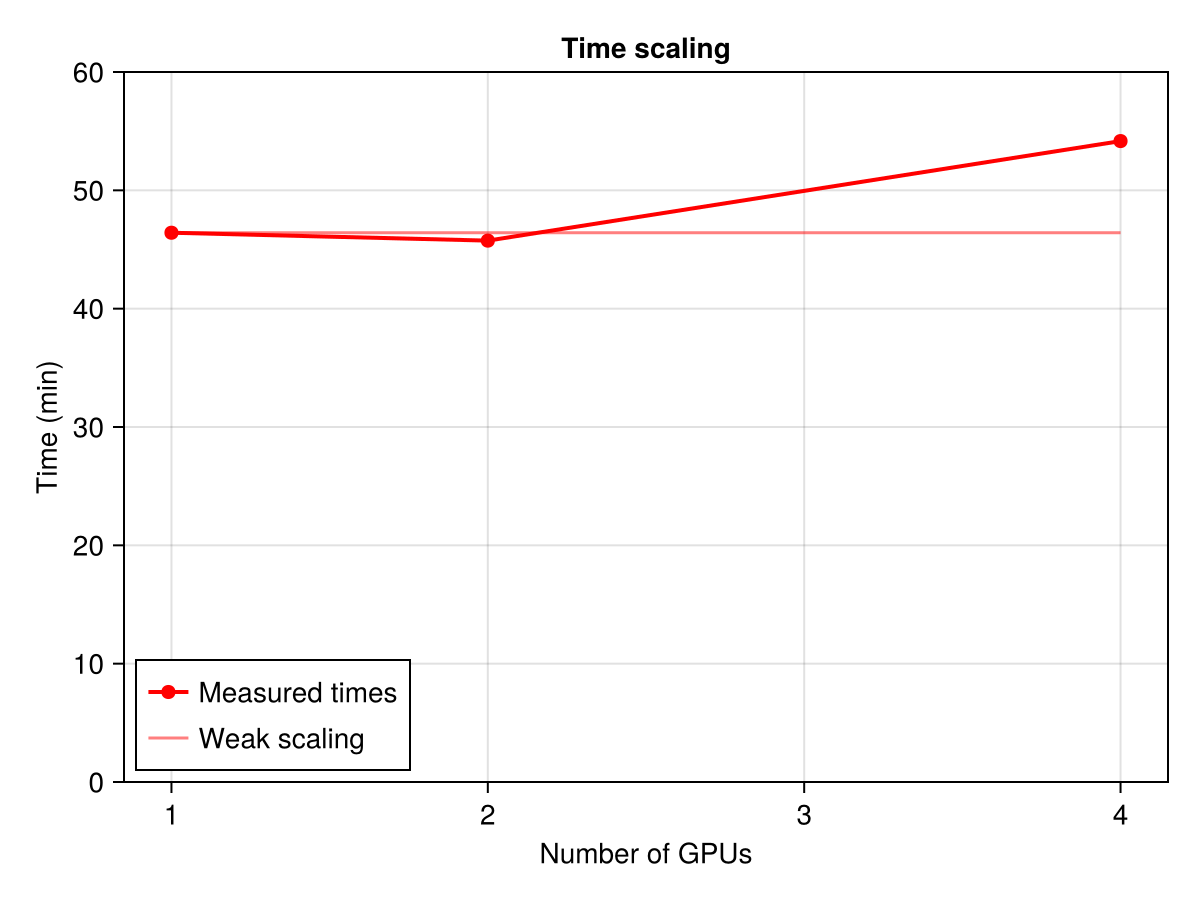

In [9]:
f = Figure()
ax = Axis(f[1, 1], xlabel = "Number of GPUs", ylabel = "Time (min)", title = "Time scaling")
scatterlines!(ax, n, times, linewidth = 2, marker = :circle, markersize = 10, label = "Measured times", color = :red)
lines!(ax, range(1, 4, 100), range(times[1], times[1], 100), label = "Weak scaling", color = :red, alpha = 0.5)
ylims!(0, 60)
axislegend(ax, position = :lb)
save("time_weak.svg", f)
f